In [1]:
import os

zip_path = r"C:\Users\shivam shilpkar\Downloads\IDC409_Project_raw_data.zip"

print("File exists:", os.path.exists(zip_path))

File exists: True


In [2]:
import os
import pandas as pd

for root, dirs, files in os.walk("student_data"):
    for file in files:
        if file == "student-mat.csv":
            csv_path = os.path.join(root, file)

df = pd.read_csv(csv_path, sep=";")

print(df.head())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


In [3]:
# Select the input variables and target variable

X = df[
    ["G1", "G2", "failures", "Medu", "Fedu", "studytime"]
]

y = df["G3"]

print("Input data:")
print(X.head())

print("\nTarget (final grades):")
print(y.head())

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

Input data:
   G1  G2  failures  Medu  Fedu  studytime
0   5   6         0     4     4          2
1   5   5         0     1     1          2
2   7   8         3     1     1          2
3  15  14         0     4     2          3
4   6  10         0     3     3          2

Target (final grades):
0     6
1     6
2    10
3    15
4    10
Name: G3, dtype: int64

Input shape: (395, 6)
Target shape: (395,)


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=62
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 316
Testing samples: 79


In [5]:
from sklearn.ensemble import RandomForestRegressor

regressor = RandomForestRegressor(
    n_estimators=100,
    random_state=62
)

regressor.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [6]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

predictions = regressor.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"MAE  = {mae:.3f}")
print(f"RMSE = {rmse:.3f}")
print(f"R²   = {r2:.3f}")

MAE  = 1.174
RMSE = 2.162
R²   = 0.737


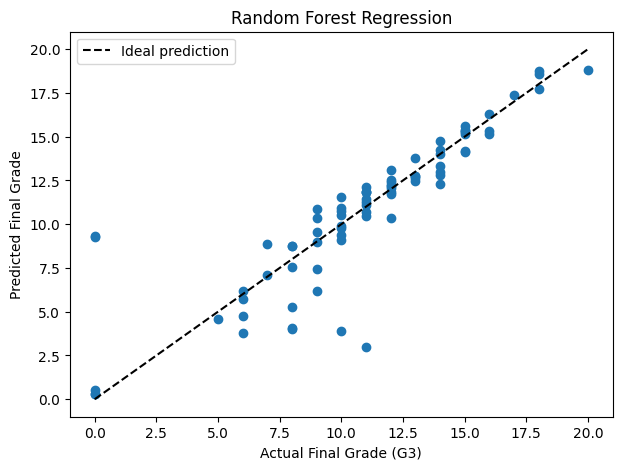

In [7]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 5))

plt.scatter(y_test, predictions)

plt.plot(
    [0, 20],
    [0, 20],
    color='black',
    linestyle='--',
    label='Ideal prediction'
)

plt.xlabel('Actual Final Grade (G3)')
plt.ylabel('Predicted Final Grade')
plt.title('Random Forest Regression')
plt.legend()
plt.show()